In [79]:
import os
import numpy as np
import pandas as pd
import joblib
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch version: 2.14.1+cpu
CUDA available: False


In [82]:
DATA_PATH = Path(
    "/content/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

raw_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", raw_df.shape)

display(raw_df.head())

Dataset loaded successfully!
Shape: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [83]:
raw_df["datetime"] = pd.to_datetime(
    raw_df[["year", "month", "day", "hour"]]
)

raw_df = raw_df.set_index("datetime")
raw_df = raw_df.sort_index()

print("Datetime index created successfully!")
print("Index type:", type(raw_df.index))
print("First timestamp:", raw_df.index.min())
print("Last timestamp:", raw_df.index.max())
print("Duplicate timestamps:", raw_df.index.duplicated().sum())

display(raw_df.head())

Datetime index created successfully!
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
First timestamp: 2013-03-01 00:00:00
Last timestamp: 2017-02-28 23:00:00
Duplicate timestamps: 0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
datetime,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
2013-03-01 01:00:00,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2013-03-01 02:00:00,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
2013-03-01 04:00:00,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [84]:
print("Dataset shape:", raw_df.shape)

print("\nMissing values in original columns:")
display(raw_df.isnull().sum().to_frame("Missing_Count"))

print("\nHourly frequency:")
print(raw_df.index.to_series().diff().value_counts().head())

print("\nMissing hourly timestamps:")
expected_index = pd.date_range(
    start=raw_df.index.min(),
    end=raw_df.index.max(),
    freq="h"
)

missing_timestamps = expected_index.difference(raw_df.index)

print("Missing timestamps:", len(missing_timestamps))

Dataset shape: (35064, 18)

Missing values in original columns:


,Missing_Count
No,0
year,0
month,0
day,0
hour,0
PM2.5,925
PM10,718
SO2,935
NO2,1023
CO,1776



Hourly frequency:
datetime
0 days 01:00:00    35063
Name: count, dtype: int64

Missing hourly timestamps:
Missing timestamps: 0


In [85]:
MODEL_DIR = Path("models")
FEATURE_PATH = MODEL_DIR / "lstm_feature_columns.pkl"

print("Feature file exists:", FEATURE_PATH.exists())

if not FEATURE_PATH.exists():
    raise FileNotFoundError(
        "Upload lstm_feature_columns.pkl into the models folder."
    )

training_columns = joblib.load(FEATURE_PATH)

print("\nExpected feature count:", len(training_columns))
print("\nExpected feature order:")
for i, col in enumerate(training_columns, start=1):
    print(i, col)

Feature file exists: True

Expected feature count: 50

Expected feature order:
1 No
2 year
3 month
4 day
5 hour
6 PM2.5
7 PM10
8 SO2
9 NO2
10 CO
11 O3
12 TEMP
13 PRES
14 DEWP
15 RAIN
16 WSPM
17 station
18 PM2.5_lag_1h
19 PM2.5_lag_3h
20 PM2.5_lag_6h
21 PM2.5_lag_12h
22 PM2.5_lag_24h
23 PM2.5_roll_mean_3h
24 PM2.5_roll_std_3h
25 PM2.5_roll_mean_6h
26 PM2.5_roll_std_6h
27 PM2.5_roll_mean_12h
28 PM2.5_roll_std_12h
29 PM2.5_roll_mean_24h
30 PM2.5_roll_std_24h
31 dayofweek
32 hour_sin
33 hour_cos
34 month_sin
35 month_cos
36 wd_ENE
37 wd_ESE
38 wd_N
39 wd_NE
40 wd_NNE
41 wd_NNW
42 wd_NW
43 wd_S
44 wd_SE
45 wd_SSE
46 wd_SSW
47 wd_SW
48 wd_W
49 wd_WNW
50 wd_WSW


In [86]:
SCALER_X_PATH = MODEL_DIR / "lstm_scaler_X.pkl"
SCALER_Y_PATH = MODEL_DIR / "lstm_scaler_y.pkl"

print("X scaler exists:", SCALER_X_PATH.exists())
print("Y scaler exists:", SCALER_Y_PATH.exists())

if not SCALER_X_PATH.exists() or not SCALER_Y_PATH.exists():
    raise FileNotFoundError("One or both scaler files are missing.")

scaler_X = joblib.load(SCALER_X_PATH)
scaler_y = joblib.load(SCALER_Y_PATH)

print("\nX scaler type:", type(scaler_X).__name__)
print("Y scaler type:", type(scaler_y).__name__)

print("\nX scaler expected feature count:",
      getattr(scaler_X, "n_features_in_", "Not available"))

print("Y scaler expected feature count:",
      getattr(scaler_y, "n_features_in_", "Not available"))

print("\nX scaler feature names:")
print(getattr(scaler_X, "feature_names_in_", "Not stored"))

X scaler exists: True
Y scaler exists: True

X scaler type: StandardScaler
Y scaler type: StandardScaler

X scaler expected feature count: 50
Y scaler expected feature count: 1

X scaler feature names:
Not stored


In [87]:
print("Original feature data types:")
display(raw_df[training_columns[:17]].dtypes.to_frame("Data_Type"))

station_position = training_columns.index("station")

print("\nStation values in original dataset:")
print(raw_df["station"].unique())

print("\nStation feature position:", station_position)
print("Saved scaler mean for station:",
      scaler_X.mean_[station_position])
print("Saved scaler scale for station:",
      scaler_X.scale_[station_position])

print("\nWind-direction feature columns:")
print([col for col in training_columns if col.startswith("wd_")])

Original feature data types:


,Data_Type
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64



Station values in original dataset:
['Aotizhongxin']

Station feature position: 16
Saved scaler mean for station: 0.0
Saved scaler scale for station: 1.0

Wind-direction feature columns:
['wd_ENE', 'wd_ESE', 'wd_N', 'wd_NE', 'wd_NNE', 'wd_NNW', 'wd_NW', 'wd_S', 'wd_SE', 'wd_SSE', 'wd_SSW', 'wd_SW', 'wd_W', 'wd_WNW', 'wd_WSW']


In [88]:
feature_df = raw_df.copy()

# Encode the single station as zero
feature_df["station"] = 0

# Time-based features
feature_df["dayofweek"] = feature_df.index.dayofweek

feature_df["hour_sin"] = np.sin(
    2 * np.pi * feature_df["hour"] / 24
)
feature_df["hour_cos"] = np.cos(
    2 * np.pi * feature_df["hour"] / 24
)

feature_df["month_sin"] = np.sin(
    2 * np.pi * feature_df["month"] / 12
)
feature_df["month_cos"] = np.cos(
    2 * np.pi * feature_df["month"] / 12
)

# Wind-direction encoding
wind_dummies = pd.get_dummies(
    feature_df["wd"],
    prefix="wd",
    dtype=int
)

feature_df = pd.concat(
    [feature_df, wind_dummies],
    axis=1
)

# Create missing expected wind columns as zero
for col in training_columns:
    if col.startswith("wd_") and col not in feature_df.columns:
        feature_df[col] = 0

# Lag features
for lag in [1, 3, 6, 12, 24]:
    feature_df[f"PM2.5_lag_{lag}h"] = (
        feature_df["PM2.5"].shift(lag)
    )

# Rolling features using previous readings only
previous_pm25 = feature_df["PM2.5"].shift(1)

for window in [3, 6, 12, 24]:
    feature_df[f"PM2.5_roll_mean_{window}h"] = (
        previous_pm25.rolling(window=window).mean()
    )
    feature_df[f"PM2.5_roll_std_{window}h"] = (
        previous_pm25.rolling(window=window).std()
    )

# Select exact training features and order
X_inference = feature_df[training_columns].copy()

print("Feature engineering completed!")
print("Feature shape:", X_inference.shape)
print("Feature count:", len(X_inference.columns))
print("Duplicate columns:", X_inference.columns.duplicated().sum())

display(X_inference.head())

Feature engineering completed!
Feature shape: (35064, 50)
Feature count: 50
Duplicate columns: 0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,wd_NNW,wd_NW,wd_S,wd_SE,wd_SSE,wd_SSW,wd_SW,wd_W,wd_WNW,wd_WSW
datetime,,,,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,...,1,0,0,0,0,0,0,0,0,0
2013-03-01 01:00:00,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,...,0,0,0,0,0,0,0,0,0,0
2013-03-01 02:00:00,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,...,1,0,0,0,0,0,0,0,0,0
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,...,0,1,0,0,0,0,0,0,0,0
2013-03-01 04:00:00,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,...,0,0,0,0,0,0,0,0,0,0


In [89]:
cleaned_check = raw_df.dropna().copy()

print("Original dataset rows:", len(raw_df))
print("Rows after dropping missing values:", len(cleaned_check))
print("Expected training-cleaned rows: 33902")

print("\nDoes the row count match?",
      len(cleaned_check) == 33902)

print("\nFirst timestamp:", cleaned_check.index.min())
print("Last timestamp:", cleaned_check.index.max())

print("\nMissing values remaining:",
      cleaned_check.isnull().sum().sum())

Original dataset rows: 35064
Rows after dropping missing values: 31815
Expected training-cleaned rows: 33902

Does the row count match? False

First timestamp: 2013-03-01 00:00:00
Last timestamp: 2017-02-28 23:00:00

Missing values remaining: 0


In [90]:
pm25_missing = raw_df["PM2.5"].isnull()

groups = pm25_missing.ne(
    pm25_missing.shift(fill_value=False)
).cumsum()

missing_runs = (
    raw_df.loc[pm25_missing]
    .groupby(groups[pm25_missing])
    .agg(
        Start=("PM2.5", lambda x: x.index.min()),
        End=("PM2.5", lambda x: x.index.max()),
        Missing_Hours=("PM2.5", "size")
    )
)

print("Total missing PM2.5 readings:",
      pm25_missing.sum())

print("Number of consecutive missing periods:",
      len(missing_runs))

print("\nMissing-period length distribution:")
display(missing_runs["Missing_Hours"].value_counts().sort_index().to_frame(
    "Number_of_Periods"
))

print("\nFirst 10 missing periods:")
display(missing_runs.head(10))

Total missing PM2.5 readings: 925
Number of consecutive missing periods: 209

Missing-period length distribution:


,Number_of_Periods
Missing_Hours,
1,115
2,59
3,12
4,5
5,4
6,1
7,1
8,1
15,2



First 10 missing periods:


,Start,End,Missing_Hours
PM2.5,,,
1,2013-05-02 21:00:00,2013-05-02 21:00:00,1
3,2013-05-16 13:00:00,2013-05-16 13:00:00,1
5,2013-06-07 16:00:00,2013-06-07 16:00:00,1
7,2013-06-25 01:00:00,2013-06-25 01:00:00,1
9,2013-06-26 00:00:00,2013-06-26 00:00:00,1
11,2013-08-22 11:00:00,2013-08-22 11:00:00,1
13,2013-09-29 15:00:00,2013-09-29 15:00:00,1
15,2013-10-22 12:00:00,2013-10-22 12:00:00,1
17,2013-11-07 15:00:00,2013-11-07 15:00:00,1


In [91]:
# Identify rows where all 50 features are available
valid_rows = X_inference.notna().all(axis=1)

# Identify continuous blocks of valid rows
block_id = (~valid_rows).cumsum()

valid_blocks = (
    valid_rows[valid_rows]
    .groupby(block_id[valid_rows])
    .size()
)

# Count possible 24-hour sequences in each block
sequence_length = 24

possible_sequences = (
    valid_blocks - sequence_length + 1
).clip(lower=0)

print("Total dataset rows:", len(X_inference))
print("Rows with all 50 valid features:", valid_rows.sum())
print("Continuous valid blocks:", len(valid_blocks))
print("Largest valid block:", valid_blocks.max())

print("\nPossible 24-hour sequences:",
      possible_sequences.sum())

print("\nValid block length summary:")
display(valid_blocks.describe().to_frame("Hours"))

Total dataset rows: 35064
Rows with all 50 valid features: 28110
Continuous valid blocks: 789
Largest valid block: 631

Possible 24-hour sequences: 16213

Valid block length summary:


,Hours
count,789.000000
mean,35.627376
std,52.334201
min,1.000000
25%,5.000000
50%,22.000000
75%,47.000000
max,631.000000


In [92]:
complete_data = X_inference.loc[
    X_inference.notna().all(axis=1)
]

comparison = pd.DataFrame({
    "Training_Mean": scaler_X.mean_,
    "Inference_Mean": complete_data.mean().values,
    "Training_Std": scaler_X.scale_,
    "Inference_Std": complete_data.std().values
}, index=training_columns)

comparison["Mean_Difference"] = (
    comparison["Inference_Mean"] - comparison["Training_Mean"]
).abs()

print("Training vs inference feature statistics:")
display(comparison.round(3))

print("\nLargest mean differences:")
display(
    comparison.sort_values(
        "Mean_Difference", ascending=False
    ).head(15).round(3)
)

Training vs inference feature statistics:


,Training_Mean,Inference_Mean,Training_Std,Inference_Std,Mean_Difference
No,12587.253,17584.718,7173.876,10257.173,4997.465
year,2014.084,2014.676,0.802,1.184,0.592
month,6.713,6.441,3.282,3.420,0.272
day,15.523,15.506,8.792,8.796,0.017
hour,11.533,11.616,6.907,6.931,0.083
PM2.5,85.336,82.681,81.791,80.990,2.655
PM10,116.010,109.984,96.683,94.557,6.026
SO2,19.379,17.384,24.713,22.812,1.995
NO2,62.700,59.343,36.979,37.191,3.357
CO,1270.805,1269.642,1222.957,1233.237,1.163



Largest mean differences:


,Training_Mean,Inference_Mean,Training_Std,Inference_Std,Mean_Difference
No,12587.253,17584.718,7173.876,10257.173,4997.465
PM10,116.010,109.984,96.683,94.557,6.026
NO2,62.700,59.343,36.979,37.191,3.357
PM2.5_lag_1h,85.336,82.635,81.790,81.038,2.701
PM2.5,85.336,82.681,81.791,80.990,2.655
PM2.5_roll_mean_3h,85.336,82.689,80.464,79.909,2.647
PM2.5_lag_3h,85.336,82.746,81.791,81.154,2.589
PM2.5_roll_mean_6h,85.335,82.788,78.600,78.187,2.547
PM2.5_lag_6h,85.334,82.958,81.792,81.392,2.376
PM2.5_roll_mean_12h,85.333,82.983,75.224,74.866,2.350


In [93]:
MODEL_PATH = MODEL_DIR / "lstm_next_hour.pth"

print("Model file exists:", MODEL_PATH.exists())

if not MODEL_PATH.exists():
    raise FileNotFoundError("lstm_next_hour.pth is missing.")

checkpoint = torch.load(
    MODEL_PATH,
    map_location=torch.device("cpu"),
    weights_only=True
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    print(list(checkpoint.keys()))

    print("\nModel parameter shapes:")
    state_dict = checkpoint.get("model_state_dict", checkpoint)

    for name, value in state_dict.items():
        if isinstance(value, torch.Tensor):
            print(name, tuple(value.shape))

Model file exists: True

Checkpoint type: <class 'dict'>

Checkpoint keys:
['model_state_dict', 'input_size', 'hidden_size', 'num_layers', 'seq_len']

Model parameter shapes:
lstm.weight_ih_l0 (256, 50)
lstm.weight_hh_l0 (256, 64)
lstm.bias_ih_l0 (256,)
lstm.bias_hh_l0 (256,)
lstm.weight_ih_l1 (256, 64)
lstm.weight_hh_l1 (256, 64)
lstm.bias_ih_l1 (256,)
lstm.bias_hh_l1 (256,)
fc.weight (1, 64)
fc.bias (1,)


In [94]:
# Read architecture settings from checkpoint
input_size = checkpoint["input_size"]
hidden_size = checkpoint["hidden_size"]
num_layers = checkpoint["num_layers"]
seq_len = checkpoint["seq_len"]

# Recreate the LSTM architecture
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        output = output[:, -1, :]
        return self.fc(output)

# Initialize model
model = LSTMModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers
)

# Load trained weights
model.load_state_dict(checkpoint["model_state_dict"])

# Set evaluation mode
model.eval()

print("LSTM model loaded successfully!")
print("Input size:", input_size)
print("Hidden size:", hidden_size)
print("Number of layers:", num_layers)
print("Sequence length:", seq_len)
print("Model mode: Evaluation")

LSTM model loaded successfully!
Input size: 50
Hidden size: 64
Number of layers: 2
Sequence length: 24
Model mode: Evaluation


In [95]:
# Identify rows where all 50 required features are available
valid_feature_mask = X_inference.notna().all(axis=1)

# Keep only rows with complete input features
valid_feature_df = X_inference.loc[
    valid_feature_mask
].copy()

print("Input preparation completed!")
print("Original rows:", len(X_inference))
print("Rows with complete features:", len(valid_feature_df))
print("Rows excluded due to missing features:",
      len(X_inference) - len(valid_feature_df))

print("\nRemaining missing values:",
      valid_feature_df.isnull().sum().sum())

print("\nFirst valid rows:")
display(valid_feature_df.head())

Input preparation completed!
Original rows: 35064
Rows with complete features: 28110
Rows excluded due to missing features: 6954

Remaining missing values: 0

First valid rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,wd_NNW,wd_NW,wd_S,wd_SE,wd_SSE,wd_SSW,wd_SW,wd_W,wd_WNW,wd_WSW
datetime,,,,,,,,,,,,,,,,,,,,,
2013-03-02 00:00:00,25,2013,3,2,0,22.0,24.0,24.0,44.0,500.0,...,0,0,0,0,0,0,0,0,0,0
2013-03-02 01:00:00,26,2013,3,2,1,14.0,17.0,21.0,36.0,400.0,...,0,0,0,0,0,0,0,0,0,0
2013-03-02 02:00:00,27,2013,3,2,2,13.0,13.0,20.0,37.0,400.0,...,0,0,0,0,0,0,0,0,0,0
2013-03-02 03:00:00,28,2013,3,2,3,3.0,9.0,13.0,34.0,400.0,...,0,0,0,0,0,0,0,0,0,0
2013-03-02 04:00:00,29,2013,3,2,4,3.0,7.0,18.0,43.0,400.0,...,1,0,0,0,0,0,0,0,0,0


In [96]:
sequence_data = []
sequence_timestamps = []

for i in range(len(X_inference) - seq_len + 1):

    window = X_inference.iloc[i:i + seq_len]

    # Check that all 24 timestamps are consecutive
    expected_times = pd.date_range(
        start=window.index[0],
        periods=seq_len,
        freq="h"
    )

    if not window.index.equals(expected_times):
        continue

    # Check that all 50 features are available
    if window.isna().any().any():
        continue

    sequence_data.append(window.values)
    sequence_timestamps.append(window.index[-1])

X_sequences = np.array(sequence_data, dtype=np.float32)

print("Sequence preparation completed!")
print("Sequence shape:", X_sequences.shape)
print("Sequence length:", seq_len)
print("Features per sequence:", input_size)
print("Valid sequences:", len(X_sequences))

Sequence preparation completed!
Sequence shape: (16213, 24, 50)
Sequence length: 24
Features per sequence: 50
Valid sequences: 16213


In [97]:
# Reshape sequences for scaling
n_samples, n_steps, n_features = X_sequences.shape

X_reshaped = X_sequences.reshape(-1, n_features)

# Apply the saved training scaler
X_scaled_reshaped = scaler_X.transform(X_reshaped)

# Restore the 3D LSTM input shape
X_scaled = X_scaled_reshaped.reshape(
    n_samples,
    n_steps,
    n_features
)

print("Input scaling completed!")
print("Scaled input shape:", X_scaled.shape)
print("Minimum scaled value:", np.min(X_scaled))
print("Maximum scaled value:", np.max(X_scaled))
print("Contains NaN:", np.isnan(X_scaled).any())
print("Contains infinity:", np.isinf(X_scaled).any())

Input scaling completed!
Scaled input shape: (16213, 24, 50)
Minimum scaled value: -2.7465453
Maximum scaled value: 43.664135
Contains NaN: False
Contains infinity: False


In [98]:
# Convert input to PyTorch tensor
X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32
)

# Generate predictions
model.eval()

with torch.no_grad():
    predictions_scaled = model(X_tensor).cpu().numpy()

print("LSTM prediction completed!")
print("Prediction shape:", predictions_scaled.shape)
print("\nFirst 10 scaled predictions:")
print(predictions_scaled[:10].flatten())

LSTM prediction completed!
Prediction shape: (16213, 1)

First 10 scaled predictions:
[-0.11615457  0.02341441  0.11068196  0.1949049   0.17723256  0.19167984
  0.02783585  0.1674822   0.17001233  0.1137779 ]


In [99]:
# Convert scaled predictions to original PM2.5 units
predictions = scaler_y.inverse_transform(
    predictions_scaled
).flatten()

print("Inverse scaling completed!")
print("Prediction count:", len(predictions))

print("\nFirst 10 PM2.5 predictions (µg/m³):")
print(predictions[:10])

print("\nMinimum predicted PM2.5:", predictions.min())
print("Maximum predicted PM2.5:", predictions.max())
print("Mean predicted PM2.5:", predictions.mean())
print("Contains NaN:", np.isnan(predictions).any())

Inverse scaling completed!
Prediction count: 16213

First 10 PM2.5 predictions (µg/m³):
[ 75.83489  87.25039  94.38809 101.27677  99.83133 101.01299  87.61202
  99.03384  99.24078  94.64131]

Minimum predicted PM2.5: 1.0766225
Maximum predicted PM2.5: 501.9546
Mean predicted PM2.5: 83.761566
Contains NaN: False


In [100]:
prediction_timestamps = (
    pd.DatetimeIndex(sequence_timestamps)
    + pd.Timedelta(hours=1)
)

prediction_results = pd.DataFrame({
    "Input_Last_Hour": sequence_timestamps,
    "Prediction_Time": prediction_timestamps,
    "Predicted_PM2.5": predictions
})

print("Prediction results created!")
print("Total predictions:", len(prediction_results))

display(prediction_results.head(10))

print("\nPrediction timestamp range:")
print(prediction_results["Prediction_Time"].min())
print(prediction_results["Prediction_Time"].max())

Prediction results created!
Total predictions: 16213


,Input_Last_Hour,Prediction_Time,Predicted_PM2.5
0,2013-03-02 23:00:00,2013-03-03 00:00:00,75.834892
1,2013-03-03 00:00:00,2013-03-03 01:00:00,87.250389
2,2013-03-03 01:00:00,2013-03-03 02:00:00,94.388092
3,2013-03-03 02:00:00,2013-03-03 03:00:00,101.276772
4,2013-03-03 03:00:00,2013-03-03 04:00:00,99.831329
5,2013-03-03 04:00:00,2013-03-03 05:00:00,101.012993
6,2013-03-03 05:00:00,2013-03-03 06:00:00,87.612022
7,2013-03-03 06:00:00,2013-03-03 07:00:00,99.033836
8,2013-03-03 07:00:00,2013-03-03 08:00:00,99.240784
9,2013-03-03 08:00:00,2013-03-03 09:00:00,94.641312



Prediction timestamp range:
2013-03-03 00:00:00
2017-02-27 11:00:00


In [101]:
# Get actual PM2.5 readings at prediction timestamps
actual_values = raw_df["PM2.5"].reindex(
    prediction_results["Prediction_Time"]
)

prediction_results["Actual_PM2.5"] = (
    actual_values.to_numpy()
)

# Identify predictions with available actual readings
evaluation_data = prediction_results.dropna(
    subset=["Actual_PM2.5"]
).copy()

print("Actual-value matching completed!")
print("Total predictions:", len(prediction_results))
print("Predictions with actual values:", len(evaluation_data))
print("Predictions without actual values:",
      len(prediction_results) - len(evaluation_data))

print("\nFirst 10 matched results:")
display(evaluation_data.head(10))

Actual-value matching completed!
Total predictions: 16213
Predictions with actual values: 16153
Predictions without actual values: 60

First 10 matched results:


,Input_Last_Hour,Prediction_Time,Predicted_PM2.5,Actual_PM2.5
0,2013-03-02 23:00:00,2013-03-03 00:00:00,75.834892,112.0
1,2013-03-03 00:00:00,2013-03-03 01:00:00,87.250389,109.0
2,2013-03-03 01:00:00,2013-03-03 02:00:00,94.388092,110.0
3,2013-03-03 02:00:00,2013-03-03 03:00:00,101.276772,105.0
4,2013-03-03 03:00:00,2013-03-03 04:00:00,99.831329,106.0
5,2013-03-03 04:00:00,2013-03-03 05:00:00,101.012993,101.0
6,2013-03-03 05:00:00,2013-03-03 06:00:00,87.612022,91.0
7,2013-03-03 06:00:00,2013-03-03 07:00:00,99.033836,79.0
8,2013-03-03 07:00:00,2013-03-03 08:00:00,99.240784,77.0
9,2013-03-03 08:00:00,2013-03-03 09:00:00,94.641312,83.0


In [102]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_true = evaluation_data["Actual_PM2.5"].values
y_pred = evaluation_data["Predicted_PM2.5"].values

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print("LSTM Inference Evaluation")
print("-------------------------")
print("Evaluation samples:", len(y_true))
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

LSTM Inference Evaluation
-------------------------
Evaluation samples: 16153
MAE:  12.3788
RMSE: 19.7986
R²:   0.9408


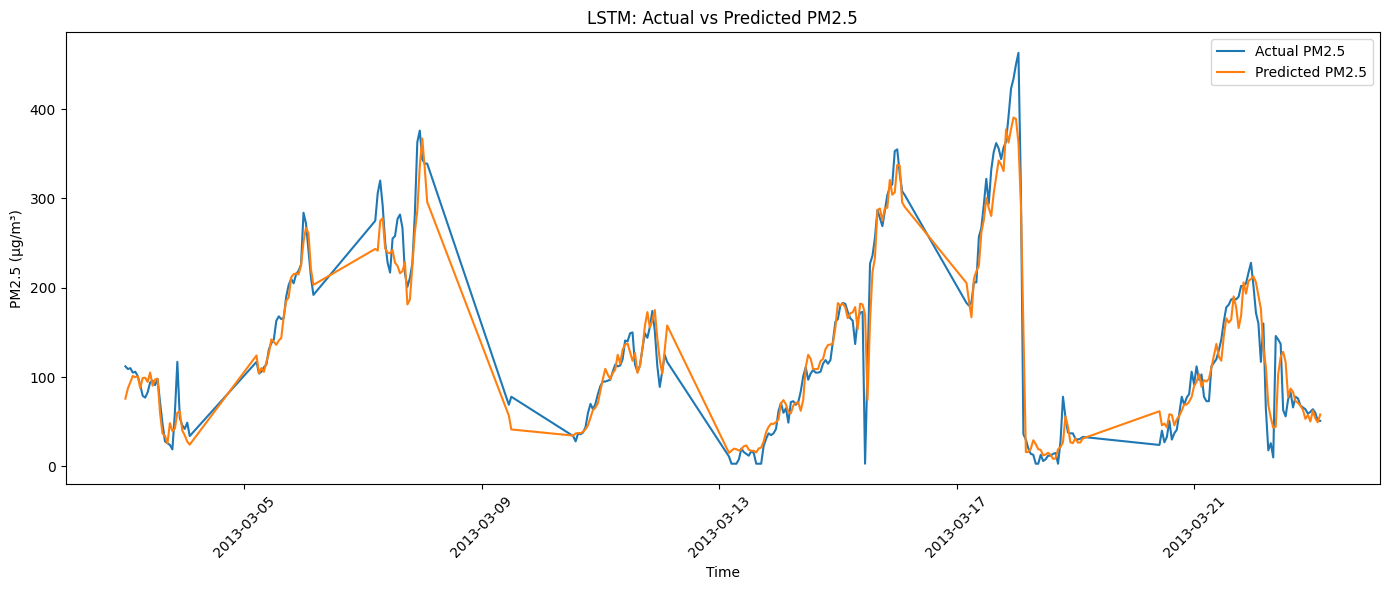

In [103]:
plt.figure(figsize=(14, 6))

plt.plot(
    evaluation_data["Prediction_Time"].iloc[:300],
    y_true[:300],
    label="Actual PM2.5"
)

plt.plot(
    evaluation_data["Prediction_Time"].iloc[:300],
    y_pred[:300],
    label="Predicted PM2.5"
)

plt.xlabel("Time")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("LSTM: Actual vs Predicted PM2.5")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

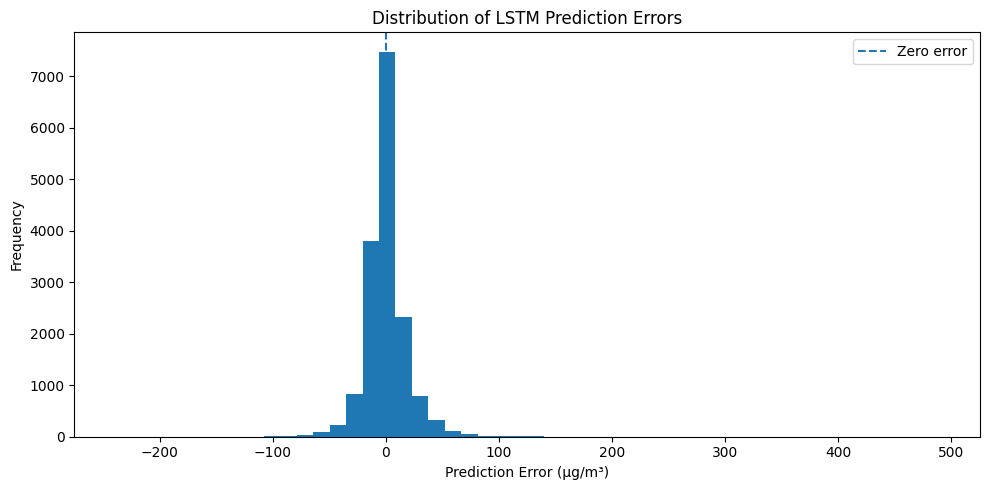

Mean prediction error: 0.1810655750741547
Standard deviation: 19.79781124162831


In [104]:
residuals = y_true - y_pred

plt.figure(figsize=(10, 5))

plt.hist(residuals, bins=50)

plt.axvline(
    0,
    linestyle="--",
    label="Zero error"
)

plt.xlabel("Prediction Error (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of LSTM Prediction Errors")
plt.legend()
plt.tight_layout()
plt.show()

print("Mean prediction error:", np.mean(residuals))
print("Standard deviation:", np.std(residuals))

In [105]:
# Add prediction errors to results
prediction_results["Prediction_Error"] = (
    prediction_results["Actual_PM2.5"]
    - prediction_results["Predicted_PM2.5"]
)

# Save complete prediction results
output_path = "/content/lstm_pm25_predictions.csv"

prediction_results.to_csv(
    output_path,
    index=False
)

print("Prediction results saved successfully!")
print("File:", output_path)
print("Total records:", len(prediction_results))
print("Columns:", list(prediction_results.columns))

# Verify saved file
print("\nFile exists:", os.path.exists(output_path))
print("File size:", round(os.path.getsize(output_path) / 1024, 2), "KB")

Prediction results saved successfully!
File: /content/lstm_pm25_predictions.csv
Total records: 16213
Columns: ['Input_Last_Hour', 'Prediction_Time', 'Predicted_PM2.5', 'Actual_PM2.5', 'Prediction_Error']

File exists: True
File size: 1166.39 KB


In [106]:
from google.colab import files

files.download("/content/lstm_pm25_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>